# Olist E-commerce Analytics: Sales and Delivery Performance

## Introduction
This notebook analyses about 99,000 orders from Olist, a Brazilian online marketplace, placed between September 2016 and October 2018. The data is public on Kaggle ("Brazilian E-commerce Public Dataset by Olist").

The aim is to answer three business questions: how did sales develop overtime, which states have the most late deliveries, and how are late deliveries related to customer review scores?

**Workflow:** load and clean the data, analyse sales and delivery with pandas and SQL (SQLite), and summarise the findings. The results are also shown in an interactive dashboard: https://guntimanoj-olist.streamlit.app

**Main result:** 8.1% of delivered orders arrived late, with rates up to 23.9% in some states, and late orders received much lower review scores (2.57 stars against 4.29).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
from google.colab import files

uploaded = files.upload()

Saving olist_customers_dataset.csv to olist_customers_dataset.csv
Saving olist_geolocation_dataset.csv to olist_geolocation_dataset.csv
Saving olist_order_items_dataset.csv to olist_order_items_dataset.csv
Saving olist_order_payments_dataset.csv to olist_order_payments_dataset.csv
Saving olist_order_reviews_dataset.csv to olist_order_reviews_dataset.csv
Saving olist_orders_dataset.csv to olist_orders_dataset.csv
Saving olist_products_dataset.csv to olist_products_dataset.csv
Saving olist_sellers_dataset.csv to olist_sellers_dataset.csv
Saving product_category_name_translation.csv to product_category_name_translation.csv


In [3]:
import os

files = os.listdir()

for file in files:
  if file.endswith(".csv"):
    print(file)

print("\nTotal CSV files:", len([f for f in files if f.endswith(".csv")]))

olist_order_reviews_dataset.csv
olist_order_payments_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_customers_dataset.csv
olist_products_dataset.csv
product_category_name_translation.csv
olist_order_items_dataset.csv
olist_sellers_dataset.csv

Total CSV files: 9


##1.  Setup and loading data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("olist_orders_dataset.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", orders.shape)

orders.head()

Dataset loaded successfully!
Rows and columns: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
print("Column names:")
print(orders.columns.tolist())

print("\nData types:")
print(orders.dtypes)

print("\nFirst 5 rows:")
display(orders.head())

print("\nDataset information:")
orders.info

Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

First 5 rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Dataset information:


<bound method DataFrame.info of                                order_id                       customer_id  \
0      e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1      53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2      47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3      949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4      ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   
...                                 ...                               ...   
99436  9c5dedf39a927c1b2549525ed64a053c  39bd1228ee8140590ac3aca26f2dfe00   
99437  63943bddc261676b46f01ca7ac2f7bd8  1fca14ff2861355f6e5f14306ff977a7   
99438  83c1379a015df1e13d02aae0204711ab  1aa71eb042121263aafbe80c1b562c9c   
99439  11c177c8e97725db2631073c19f07b62  b331b74b18dc79bcdf6532d51e1637c1   
99440  66dea50a8b16d9b4dee7af250b4be1a5  edb027a75a1449115f6b43211ae02a24   

      order_status order_purchase_timestamp    order_approved_at  \
0        delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1        delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2        delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3        delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4        delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   
...            ...                      ...                  ...   
99436    delivered      2017-03-09 09:54:05  2017-03-09 09:54:05   
99437    delivered      2018-02-06 12:58:58  2018-02-06 13:10:37   
99438    delivered      2017-08-27 14:46:43  2017-08-27 15:04:16   
99439    delivered      2018-01-08 21:28:27  2018-01-08 21:36:21   
99440    delivered      2018-03-08 20:57:30  2018-03-09 11:20:28   

      order_delivered_carrier_date order_delivered_customer_date  \
0              2017-10-04 19:55:00           2017-10-10 21:25:13   
1              2018-07-26 14:31:00           2018-08-07 15:27:45   
2              2018-08-08 13:50:00           2018-08-17 18:06:29   
3              2017-11-22 13:39:59           2017-12-02 00:28:42   
4              2018-02-14 19:46:34           2018-02-16 18:17:02   
...                            ...                           ...   
99436          2017-03-10 11:18:03           2017-03-17 15:08:01   
99437          2018-02-07 23:22:42           2018-02-28 17:37:56   
99438          2017-08-28 20:52:26           2017-09-21 11:24:17   
99439          2018-01-12 15:35:03           2018-01-25 23:32:54   
99440          2018-03-09 22:11:59           2018-03-16 13:08:30   

      order_estimated_delivery_date  
0               2017-10-18 00:00:00  
1               2018-08-13 00:00:00  
2               2018-09-04 00:00:00  
3               2017-12-15 00:00:00  
4               2018-02-26 00:00:00  
...                             ...  
99436           2017-03-28 00:00:00  
99437           2018-03-02 00:00:00  
99438           2017-09-27 00:00:00  
99439           2018-02-15 00:00:00  
99440           2018-04-03 00:00:00  

[99441 rows x 8 columns]>

## 2.  Data cleaning

In [6]:
missing_values = orders.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [7]:
print("Duplicate rows:", orders.duplicated().sum())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())

Duplicate rows: 0
Duplicate order IDs: 0


In [8]:
print("Orders statuses:")
print(orders["order_status"].value_counts())

Orders statuses:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [9]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])

print("First order date:", orders["order_purchase_timestamp"].min())
print("Last order date:", orders["order_purchase_timestamp"].max())

print("Data type:", orders["order_purchase_timestamp"].dtype)

First order date: 2016-09-04 21:15:19
Last order date: 2018-10-17 17:30:18
Data type: datetime64[ns]


In [10]:
orders_clean = orders.copy()

print("Original dataset:", orders.shape)
print("Working dataset:", orders_clean.shape)

Original dataset: (99441, 8)
Working dataset: (99441, 8)


In [11]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
  orders_clean[column] = pd.to_datetime(
      orders_clean[column],
      errors="coerce"
  )

print(orders_clean[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [12]:
orders_clean[date_columns].isnull().sum()

,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [13]:
orders_clean.groupby("order_status")[date_columns].apply(lambda x: x.isnull().sum())

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
order_status,,,,,
approved,0,0,2,2,0
canceled,0,141,550,619,0
created,0,5,5,5,0
delivered,0,14,2,8,0
invoiced,0,0,314,314,0
processing,0,0,301,301,0
shipped,0,0,0,1107,0
unavailable,0,0,609,609,0


In [14]:
duplicate_orders = orders_clean["order_id"].duplicated().sum()

print("Duplicate order IDs:", duplicate_orders)

Duplicate order IDs: 0


In [15]:
print("Missing orderIDs:", orders_clean["order_id"].isnull().sum())

Missing orderIDs: 0


In [16]:
print("Unique order IDs:", orders_clean["order_id"].nunique())
print("Total rows:", len(orders_clean))

Unique order IDs: 99441
Total rows: 99441


In [17]:
delivered_missing_date = orders_clean[
    (orders_clean["order_status"] == "delivered") &
    (orders_clean["order_delivered_customer_date"].isnull())
]

print("Delivered orders with missing delivery dates:", len(delivered_missing_date))

Delivered orders with missing delivery dates: 8


In [18]:
invalid_delivery_dates = orders_clean[
    orders_clean["order_delivered_customer_date"] < orders_clean["order_purchase_timestamp"]]

print("Orders delivered before purchase:", len(invalid_delivery_dates))

Orders delivered before purchase: 0


In [19]:
orders_clean["delivery_days"] = (
    orders_clean["order_delivered_customer_date"] - orders_clean["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

print(orders_clean[
    ["order_id", "order_purchase_timestamp",
     "order_delivered_customer_date", "delivery_days"]
].head(10))

                           order_id order_purchase_timestamp  \
0  e481f51cbdc54678b7cc49136f2d6af7      2017-10-02 10:56:33   
1  53cdb2fc8bc7dce0b6741e2150273451      2018-07-24 20:41:37   
2  47770eb9100c2d0c44946d9cf07ec65d      2018-08-08 08:38:49   
3  949d5b44dbf5de918fe9c16f97b45f8a      2017-11-18 19:28:06   
4  ad21c59c0840e6cb83a9ceb5573f8159      2018-02-13 21:18:39   
5  a4591c265e18cb1dcee52889e2d8acc3      2017-07-09 21:57:05   
6  136cce7faa42fdb2cefd53fdc79a6098      2017-04-11 12:22:08   
7  6514b8ad8028c9f2cc2374ded245783f      2017-05-16 13:10:30   
8  76c6e866289321a7c93b82b54852dc33      2017-01-23 18:29:09   
9  e69bfb5eb88e0ed6a785585b27e16dbf      2017-07-29 11:55:02   

  order_delivered_customer_date  delivery_days  
0           2017-10-10 21:25:13       8.436574  
1           2018-08-07 15:27:45      13.782037  
2           2018-08-17 18:06:29       9.394213  
3           2017-12-02 00:28:42      13.208750  
4           2018-02-16 18:17:02       2.873877  
5

In [20]:
orders_clean["late_delivery"] = (
    orders_clean["order_delivered_customer_date"] > orders_clean["order_estimated_delivery_date"]
)

print(orders_clean[
    ["order_id",
     "order_estimated_delivery_date",
     "order_delivered_customer_date",
     "late_delivery"]
].head(10))

                           order_id order_estimated_delivery_date  \
0  e481f51cbdc54678b7cc49136f2d6af7                    2017-10-18   
1  53cdb2fc8bc7dce0b6741e2150273451                    2018-08-13   
2  47770eb9100c2d0c44946d9cf07ec65d                    2018-09-04   
3  949d5b44dbf5de918fe9c16f97b45f8a                    2017-12-15   
4  ad21c59c0840e6cb83a9ceb5573f8159                    2018-02-26   
5  a4591c265e18cb1dcee52889e2d8acc3                    2017-08-01   
6  136cce7faa42fdb2cefd53fdc79a6098                    2017-05-09   
7  6514b8ad8028c9f2cc2374ded245783f                    2017-06-07   
8  76c6e866289321a7c93b82b54852dc33                    2017-03-06   
9  e69bfb5eb88e0ed6a785585b27e16dbf                    2017-08-23   

  order_delivered_customer_date  late_delivery  
0           2017-10-10 21:25:13          False  
1           2018-08-07 15:27:45          False  
2           2018-08-17 18:06:29          False  
3           2017-12-02 00:28:42          Fal

In [21]:
delivered_orders = orders_clean[orders_clean["order_status"] == "delivered"].copy()

valid_deliveries = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

valid_deliveries["late_delivery"] = (
    valid_deliveries["order_delivered_customer_date"] >
    valid_deliveries["order_estimated_delivery_date"]
)

print("Total delivered orders:", len(delivered_orders))
print("Valid deliveries:", len(valid_deliveries))
print("\nDelivery performance:")
print(valid_deliveries["late_delivery"].value_counts())

Total delivered orders: 96478
Valid deliveries: 96470

Delivery performance:
late_delivery
False    88644
True      7826
Name: count, dtype: int64


In [22]:
delivery_percentage = (
    valid_deliveries["late_delivery"].value_counts(normalize=True) * 100
).round(2)

print(delivery_percentage)

late_delivery
False    91.89
True      8.11
Name: proportion, dtype: float64


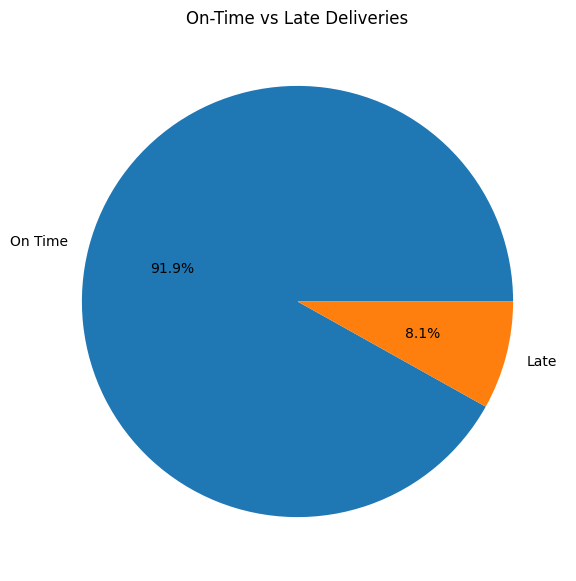

In [23]:
delivery_counts = valid_deliveries["late_delivery"].value_counts()

delivery_counts.index = ["Late" if x == True else "On Time" for x in delivery_counts.index]

delivery_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="On-Time vs Late Deliveries"
)

plt.ylabel("")
plt.show()

In [24]:
average_delivery_days = valid_deliveries["delivery_days"].mean()

print("Average delivery time:", round(average_delivery_days, 2), "days")

Average delivery time: 12.56 days


In [25]:
customers = pd.read_csv("olist_customers_dataset.csv")

print("Dataset shape:", customers.shape)
customers.head()

Dataset shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [26]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [27]:
print("Total customer records:", len(customers))

print(
    "Unique actual customers:",
    customers["customer_unique_id"].nunique()
)

Total customer records: 99441
Unique actual customers: 96096


In [28]:
top_cities = customers["customer_city"].value_counts().head(10)

print(top_cities)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: count, dtype: int64


In [29]:
states_counts = customers["customer_state"].value_counts()
print(states_counts)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64


In [30]:
state_percentage = (
    customers["customer_state"]
    .value_counts(normalize=True) * 100
).round(2)

print(state_percentage)

customer_state
SP    41.98
RJ    12.92
MG    11.70
RS     5.50
PR     5.07
SC     3.66
BA     3.40
DF     2.15
ES     2.04
GO     2.03
PE     1.66
CE     1.34
PA     0.98
MT     0.91
MA     0.75
MS     0.72
PB     0.54
PI     0.50
RN     0.49
AL     0.42
SE     0.35
TO     0.28
RO     0.25
AM     0.15
AC     0.08
AP     0.07
RR     0.05
Name: proportion, dtype: float64


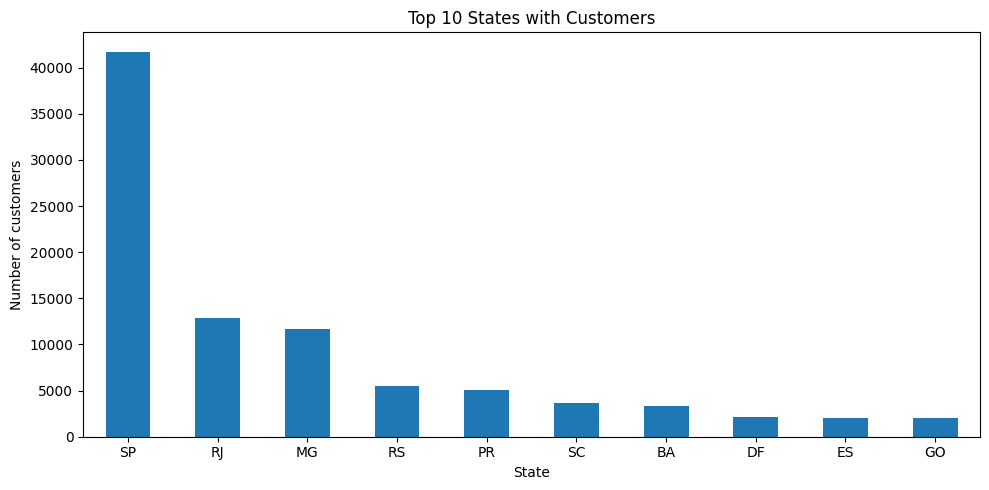

In [31]:
states_counts.head(10).plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 States with Customers"
)

plt.xlabel("State")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [32]:
print("Missing values in each column:")
print(customers.isnull().sum())

Missing values in each column:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


In [33]:
print("Completely duplicated rows:", customers.duplicated().sum())
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())

Completely duplicated rows: 0
Duplicate customer IDs: 0


In [34]:
print("Total customer records:", len(customers))

print("Unique customer IDs:", customers["customer_id"].nunique())
print("Unique actual customers:", customers["customer_id"].nunique())

Total customer records: 99441
Unique customer IDs: 99441
Unique actual customers: 99441


In [35]:
customers_clean = customers.copy()

print("Original shape:", customers.shape)
print("Cleaned working copy:", customers_clean.shape)

Original shape: (99441, 5)
Cleaned working copy: (99441, 5)


In [36]:
print("Customer ID data type:")
print(customers_clean["customer_id"].dtype)

print("\nUnique customer ID data type:")
print(customers_clean["customer_unique_id"].dtype)

Customer ID data type:
object

Unique customer ID data type:
object


In [37]:
print("Missing customers IDs:", customers_clean["customer_id"].isnull().sum())
print("Missing unique customer IDs:", customers_clean["customer_unique_id"].isnull().sum())

Missing customers IDs: 0
Missing unique customer IDs: 0


In [38]:
orders_item = pd.read_csv("olist_order_items_dataset.csv")

print("Dataset shape:", orders_item.shape)
orders_item.head()

Dataset shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [39]:
orders_item.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [40]:
order_items_clean = orders_item.copy()

order_items_clean["shipping_limit_date"] = pd.to_datetime(
    order_items_clean["shipping_limit_date"],
    errors="coerce"
)

print(order_items_clean["shipping_limit_date"].dtype)

datetime64[ns]


In [41]:
print("Duplicate rows:", order_items_clean.duplicated().sum())
print("Duplicate order items:", order_items_clean.duplicated(subset=["order_id", "order_id"]).sum()
)

Duplicate rows: 0
Duplicate order items: 13984


In [42]:
print("Zero or negative prices:", (order_items_clean["price"] <= 0).sum())
print("Negative freight values:", (order_items_clean["freight_value"] < 0).sum())
print("Missing prices", (order_items_clean["price"].isnull()).sum())
print("Missing freight values:", (order_items_clean["freight_value"].isnull()).sum())

Zero or negative prices: 0
Negative freight values: 0
Missing prices 0
Missing freight values: 0


In [43]:
print("Duplicate order-item combinations;", order_items_clean.duplicated(subset=["order_id", "order_id"]).sum())

Duplicate order-item combinations; 13984


In [44]:
duplicate_items = order_items_clean[order_items_clean.duplicated(subset=["order_id", "order_item_id"], keep=False)]

print("Duplicate records:", len(duplicate_items))
duplicate_items.head(10)

Duplicate records: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


In [45]:
print("Unique order IDs:", order_items_clean["order_id"].nunique())

print("Unique order-item IDs:", order_items_clean["order_item_id"].nunique())

print("Order item ID counts:")
print(order_items_clean["order_item_id"].value_counts().sort_index().head(10))

Unique order IDs: 98666
Unique order-item IDs: 21
Order item ID counts:
order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
Name: count, dtype: int64


In [46]:
print("Unique order IDs;", order_items_clean["order_id"].nunique())
print("Unique order-item IDs:", order_items_clean["order_item_id"].nunique())
print("\nOrder item ID counts:")

print(order_items_clean["order_item_id"].value_counts().sort_index())

Unique order IDs; 98666
Unique order-item IDs: 21

Order item ID counts:
order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64


In [47]:
print("Duplicate order-item combinations:", order_items_clean.duplicated(subset=["order_id", "order_item_id"]).sum())

Duplicate order-item combinations: 0


In [48]:
items_per_order = (order_items_clean.groupby("order_id")["order_item_id"].count())

print("Average items per order:", round(items_per_order.mean(), 2))
print("Maximum items in one order:", items_per_order.max())
print("\nNumber of orders by item count:")
print(items_per_order.value_counts().sort_index())

Average items per order: 1.14
Maximum items in one order: 21

Number of orders by item count:
order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64


In [49]:
print("PRODUCT PRICE SUMMARY")
print(order_items_clean["price"].describe())

print("\nFREIGHT VALUE SUMMARY")
print(order_items_clean["freight_value"].describe())

PRODUCT PRICE SUMMARY
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

FREIGHT VALUE SUMMARY
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


## 3. Sales and product analysis

In [50]:
delivered_items = order_items_clean.merge(orders_clean[["order_id", "order_status"]], on="order_id")
delivered_items = delivered_items[delivered_items["order_status"] == "delivered"]
total_revenue = delivered_items["price"].sum()
total_freight = delivered_items["freight_value"].sum()
print("Total product revenue:", round(total_revenue, 2))
print("Total freight value:", round(total_freight, 2))

Total product revenue: 13221498.11
Total freight value: 2198275.64


In [51]:
revenue_per_order = (delivered_items.groupby("order_id")["price"].sum())
total_revenue = revenue_per_order.sum()
total_orders = revenue_per_order.count()

aov = total_revenue / total_orders

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Order Value:", round(aov, 2))

Total Revenue: 13221498.11
Total Orders: 96478
Average Order Value: 137.04


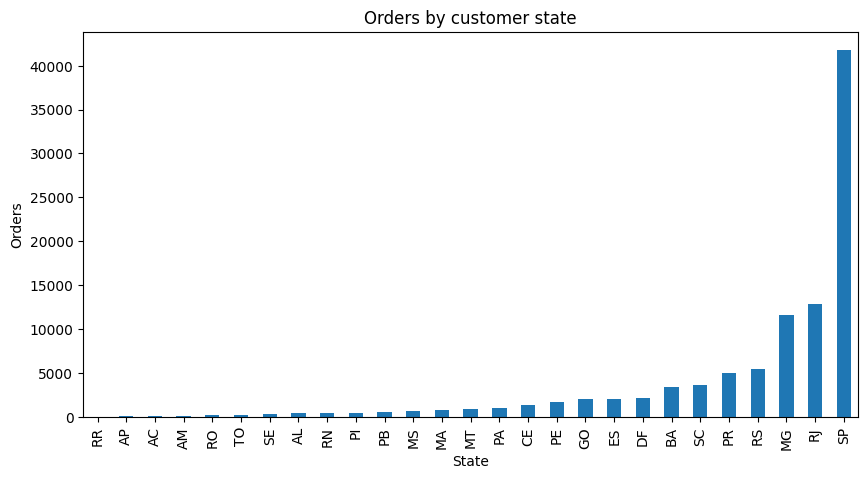

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64


In [52]:
orders_by_state = (orders_clean.merge(customers_clean[["customer_id", "customer_state"]], on="customer_id")["customer_state"].value_counts())
orders_by_state.sort_values().plot(kind="bar", figsize=(10, 5), title="Orders by customer state")
plt.xlabel("State")
plt.ylabel("Orders")
plt.show()
print(orders_by_state.head(5))

Sao Paulo (SP) is the biggest market with 41,746 orders, about 42% of all orders, roughly 3 times more than Rio de Janerio (RJ, 12,852). SP also has one of the lowest late rates (5.9%), while RJ, the second-biggest market, has 13.5%. Improving delivery in RJ would affect many more customers than fixing a small state like AL.

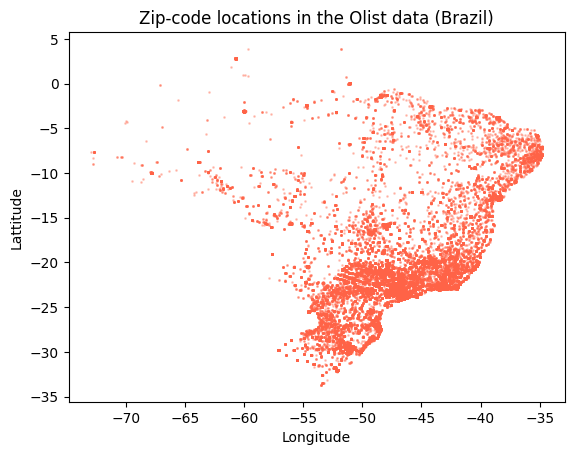

In [53]:
geo = pd.read_csv("olist_geolocation_dataset.csv")
geo = geo[geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)]
geo = geo.sample(100000, random_state=1)
plt.scatter(geo["geolocation_lng"], geo["geolocation_lat"], s=1, alpha=0.3, color="tomato")
plt.title("Zip-code locations in the Olist data (Brazil)")
plt.xlabel("Longitude")
plt.ylabel("Lattitude")
plt.show()

Most locations are on the east and south-east coast, where most of the population lives. This matches the orders-by-state chart.

In [54]:
freight_per_order = (order_items_clean.groupby("order_id")["freight_value"].sum())
average_freight = freight_per_order.mean()
total_freight = freight_per_order.sum()
print("Total freight :", round(total_freight, 2))
print("Average freight per order:", round(average_freight, 2))
print("Maximum freight per order:", round(freight_per_order.max(), 2))

Total freight : 2251909.54
Average freight per order: 22.82
Maximum freight per order: 1794.96


In [55]:
seller_revenue = (order_items_clean.groupby("seller_id")["price"].sum().sort_values(ascending=False))
print("TOP 10 SELLERS BY REVENUE")
print(seller_revenue.head(10))

TOP 10 SELLERS BY REVENUE
seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
Name: price, dtype: float64


In [56]:
seller_items = (order_items_clean.groupby("seller_id")["order_id"].count().sort_values(ascending=False))
print("TOP 10 SELLERS BY ITEMS SOLD")
print(seller_items.head(10))

TOP 10 SELLERS BY ITEMS SOLD
seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
Name: order_id, dtype: int64


In [57]:
seller_performance = pd.DataFrame({
    "total_revenue" : seller_revenue,
    "total_items" : seller_items
})

seller_performance = seller_performance.sort_values(by="total_revenue", ascending=False)

print("SELLER PERFORMANCE REPORT")
display(seller_performance.head(10))

SELLER PERFORMANCE REPORT


,total_revenue,total_items
seller_id,,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1156
53243585a1d6dc2643021fd1853d8905,222776.05,410
4a3ca9315b744ce9f8e9374361493884,200472.92,1987
fa1c13f2614d7b5c4749cbc52fecda94,194042.03,586
7c67e1448b00f6e969d365cea6b010ab,187923.89,1364
7e93a43ef30c4f03f38b393420bc753a,176431.87,340
da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1551
7a67c85e85bb2ce8582c35f2203ad736,141745.53,1171
1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1428


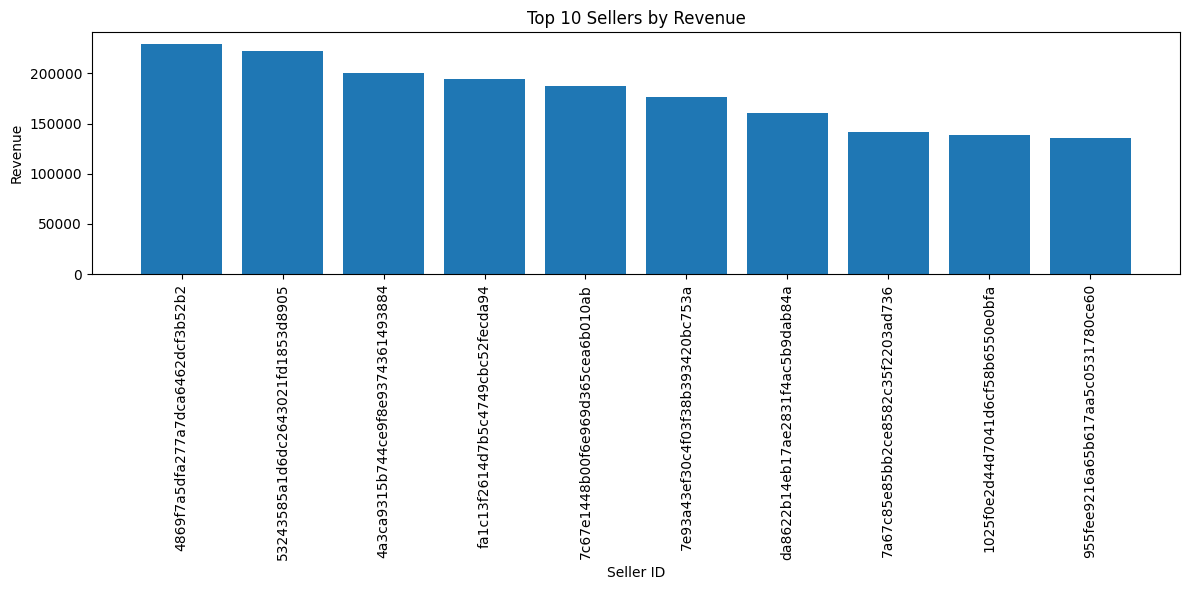

In [58]:
import matplotlib.pyplot as plt

top_sellers = seller_performance.head(10)

plt.figure(figsize=(12, 6))

plt.bar(top_sellers.index.astype(str), top_sellers["total_revenue"])

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

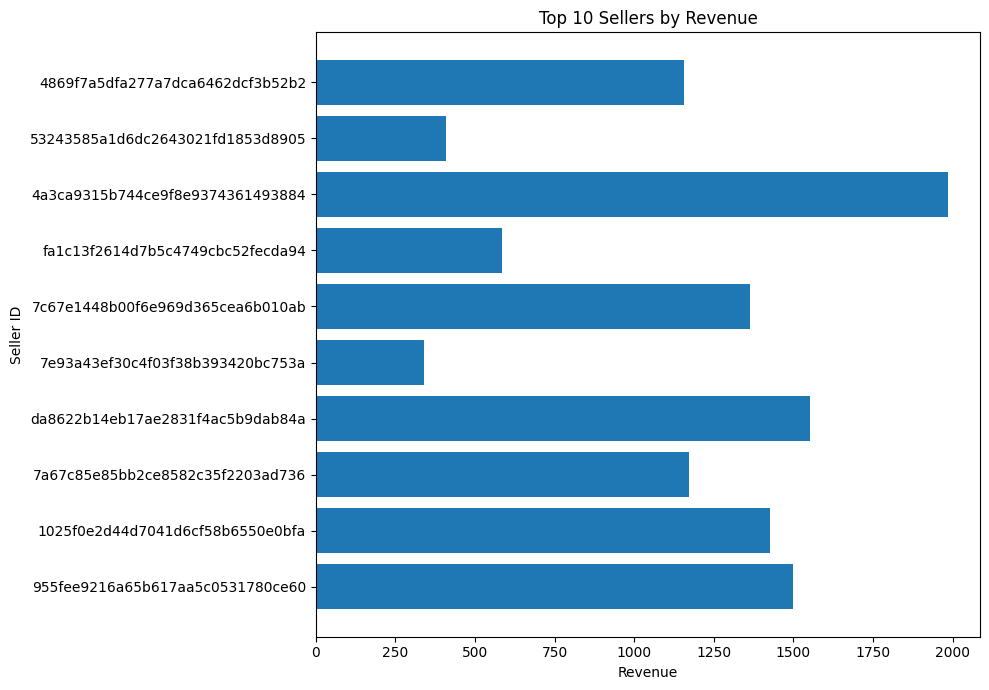

In [59]:
plt.figure(figsize=(10, 7))
plt.barh(top_sellers.index.astype(str), top_sellers["total_items"])
plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Seller ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [60]:
seller_avg_price = (order_items_clean.groupby("seller_id")["price"].mean().sort_values(ascending=False))
print("TOP 10 SELLERS BY AVERAGE ITEM PRICE")
print(seller_avg_price.head(10).round(2))

TOP 10 SELLERS BY AVERAGE ITEM PRICE
seller_id
80ceebb4ee9b31afb6c6a916a574a1e2    6729.00
ee27a8f15b1dded4d213a468ba4eb391    6499.00
585175ec331ea177fa47199e39a6170a    3549.00
abe021b01ba992245271b9aa422032df    3360.00
a00824eb9093d40e589b940ec45c4eb0    3133.32
e2a1ac9bf33e5549a2a4f834e70df2f8    2999.89
e908c0f3646e8b60375734a350d95d71    2951.00
d63c73efd41eb002280e7ec831424edb    2799.00
1444c08e64d55fb3c25f0f09c07ffcf2    2749.00
039e6ad9dae79614493083e241147386    2585.00
Name: price, dtype: float64


In [61]:
seller_final_report = seller_performance.copy()
seller_final_report["average_item_price"] = seller_avg_price

seller_final_report = seller_final_report.sort_values(by="total_revenue", ascending=False)
print("COMPLETE SELLER PERFORMANCE REPORT")
display(seller_final_report.head(10).round(2))

COMPLETE SELLER PERFORMANCE REPORT


,total_revenue,total_items,average_item_price
seller_id,,,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1156,198.51
53243585a1d6dc2643021fd1853d8905,222776.05,410,543.36
4a3ca9315b744ce9f8e9374361493884,200472.92,1987,100.89
fa1c13f2614d7b5c4749cbc52fecda94,194042.03,586,331.13
7c67e1448b00f6e969d365cea6b010ab,187923.89,1364,137.77
7e93a43ef30c4f03f38b393420bc753a,176431.87,340,518.92
da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1551,103.31
7a67c85e85bb2ce8582c35f2203ad736,141745.53,1171,121.05
1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1428,97.32


In [62]:
product_revenue = (order_items_clean.groupby("product_id")["price"].sum().sort_values(ascending=False))
print("TOP 10 PRODUCTS BY REVENUE")
print(product_revenue.head(10))

TOP 10 PRODUCTS BY REVENUE
product_id
bb50f2e236e5eea0100680137654686c    63885.00
6cdd53843498f92890544667809f1595    54730.20
d6160fb7873f184099d9bc95e30376af    48899.34
d1c427060a0f73f6b889a5c7c61f2ac4    47214.51
99a4788cb24856965c36a24e339b6058    43025.56
3dd2a17168ec895c781a9191c1e95ad7    41082.60
25c38557cf793876c5abdd5931f922db    38907.32
5f504b3a1c75b73d6151be81eb05bdc9    37733.90
53b36df67ebb7c41585e8d54d6772e08    37683.42
aca2eb7d00ea1a7b8ebd4e68314663af    37608.90
Name: price, dtype: float64


In [63]:
product_quantity = (order_items_clean.groupby("product_id")["order_id"].count().sort_values(ascending=False))
print("TOP 10 PRODUCTS BY QUANTITY SOLD")
print(product_quantity.head(10))

TOP 10 PRODUCTS BY QUANTITY SOLD
product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: order_id, dtype: int64


In [64]:
product_performance = pd.DataFrame({
    "total_revenue" : product_revenue,
    "total_quantity" : product_quantity
 })
product_performance = product_performance.sort_values(by="total_revenue", ascending=False)
print("PRODUCT PERFORMANCE REPORT")
print(product_performance.head(10).round(2))

PRODUCT PERFORMANCE REPORT
                                  total_revenue  total_quantity
product_id                                                     
bb50f2e236e5eea0100680137654686c       63885.00             195
6cdd53843498f92890544667809f1595       54730.20             156
d6160fb7873f184099d9bc95e30376af       48899.34              35
d1c427060a0f73f6b889a5c7c61f2ac4       47214.51             343
99a4788cb24856965c36a24e339b6058       43025.56             488
3dd2a17168ec895c781a9191c1e95ad7       41082.60             274
25c38557cf793876c5abdd5931f922db       38907.32              38
5f504b3a1c75b73d6151be81eb05bdc9       37733.90              63
53b36df67ebb7c41585e8d54d6772e08       37683.42             323
aca2eb7d00ea1a7b8ebd4e68314663af       37608.90             527


In [65]:
product_avg_price = (order_items_clean.groupby("product_id")["price"].mean().sort_values(ascending=False))
print("TOP 10 PRODUCTS BY AVERAGE")
print(product_avg_price)

TOP 10 PRODUCTS BY AVERAGE
product_id
489ae2aa008f021502940f251d4cce7f    6735.00
69c590f7ffc7bf8db97190b6cb6ed62e    6729.00
1bdf5e6731585cf01aa8169c7028d6ad    6499.00
a6492cc69376c469ab6f61d8f44de961    4799.00
c3ed642d592594bb648ff4a04cee2747    4690.00
                                     ...   
310dc32058903b6416c71faff132df9e       2.29
46fce52cef5caa7cc225a5531c946c8b       2.20
05b515fdc76e888aada3c6d66c201dff       1.20
270516a3f41dc035aa87d220228f844c       1.20
8a3254bee785a526d548a81a9bc3c9be       0.85
Name: price, Length: 32951, dtype: float64


In [66]:
product_final_report = pd.DataFrame({
    "total_revenue" : product_revenue,
    "total_quantity": product_quantity,
    "average_price" : product_avg_price
})
product_final_report = product_final_report.sort_values(by="total_revenue", ascending=False)
print("COMPLETE PRODUCT PERFORMANCE REPORT")
print(product_final_report.head(10).round(2))

COMPLETE PRODUCT PERFORMANCE REPORT
                                  total_revenue  total_quantity  average_price
product_id                                                                    
bb50f2e236e5eea0100680137654686c       63885.00             195         327.62
6cdd53843498f92890544667809f1595       54730.20             156         350.83
d6160fb7873f184099d9bc95e30376af       48899.34              35        1397.12
d1c427060a0f73f6b889a5c7c61f2ac4       47214.51             343         137.65
99a4788cb24856965c36a24e339b6058       43025.56             488          88.17
3dd2a17168ec895c781a9191c1e95ad7       41082.60             274         149.94
25c38557cf793876c5abdd5931f922db       38907.32              38        1023.88
5f504b3a1c75b73d6151be81eb05bdc9       37733.90              63         598.95
53b36df67ebb7c41585e8d54d6772e08       37683.42             323         116.67
aca2eb7d00ea1a7b8ebd4e68314663af       37608.90             527          71.36


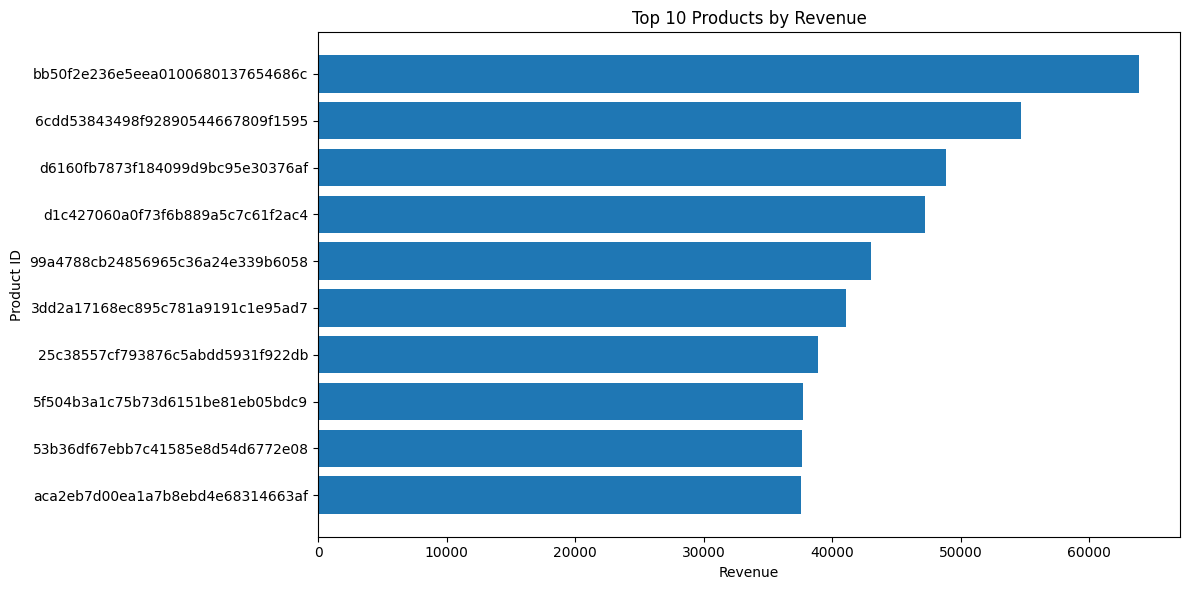

In [67]:
import matplotlib.pyplot as plt

top_products = product_final_report.head(10)
plt.figure(figsize=(12, 6))
plt.barh(top_products.index.astype(str), top_products["total_revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [68]:
top_quantity_products = product_final_report.sort_values(by="total_quantity", ascending=False).head(10)
print(top_quantity_products)

                                  total_revenue  total_quantity  average_price
product_id                                                                    
aca2eb7d00ea1a7b8ebd4e68314663af       37608.90             527      71.364137
99a4788cb24856965c36a24e339b6058       43025.56             488      88.167131
422879e10f46682990de24d770e7f83d       26577.22             484      54.911612
389d119b48cf3043d311335e499d9c6b       21440.59             392      54.695383
368c6c730842d78016ad823897a372db       21056.80             388      54.270103
53759a2ecddad2bb87a079a1f1519f73       20387.20             373      54.657373
d1c427060a0f73f6b889a5c7c61f2ac4       47214.51             343     137.651633
53b36df67ebb7c41585e8d54d6772e08       37683.42             323     116.666935
154e7e31ebfa092203795c972e5804a6        6325.19             281      22.509573
3dd2a17168ec895c781a9191c1e95ad7       41082.60             274     149.936496


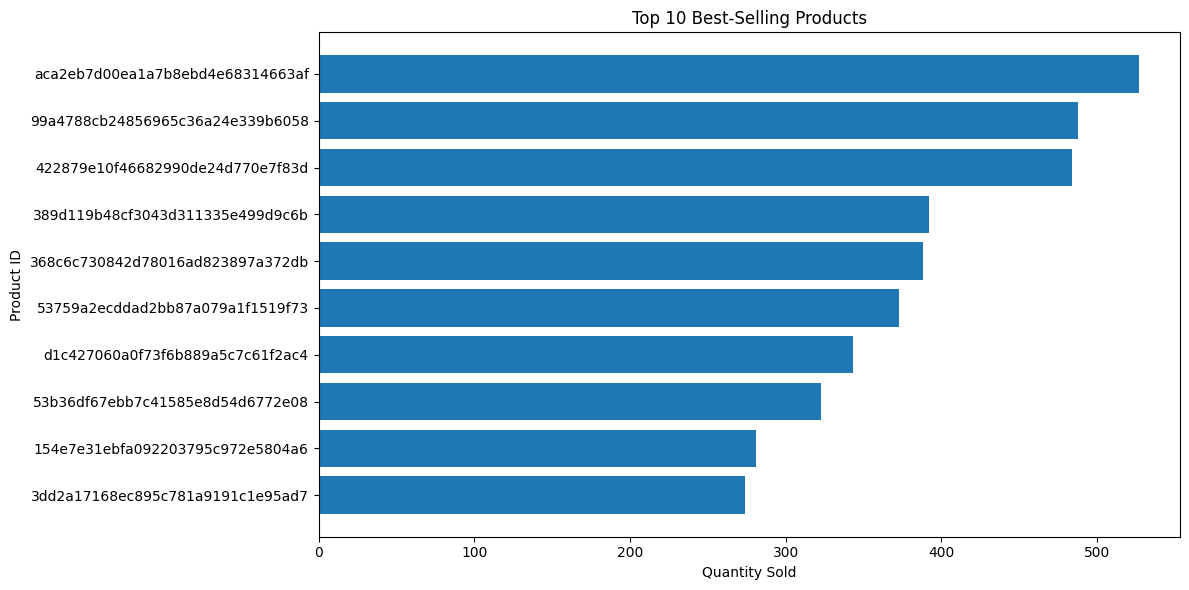

In [69]:
import matplotlib.pyplot as plt
top_quantity_products = product_final_report.sort_values(by="total_quantity", ascending=False).head(10)
plt.figure(figsize=(12, 6))
plt.barh(top_quantity_products.index.astype(str), top_quantity_products["total_quantity"])
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

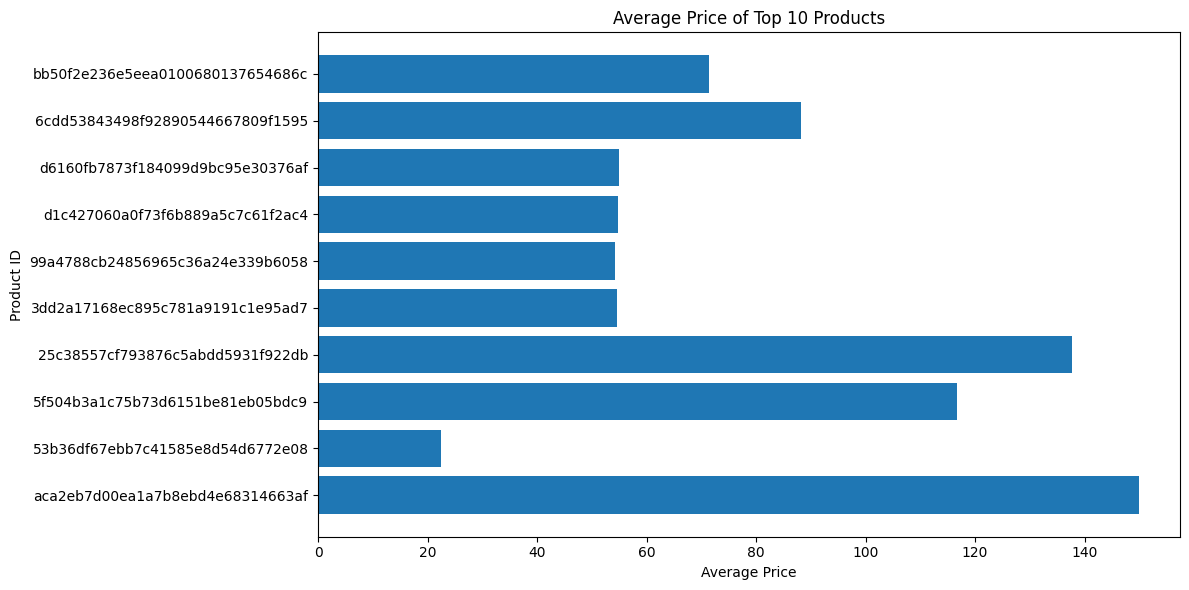

In [70]:
plt.figure(figsize=(12, 6))
plt.barh(top_products.index.astype(str), top_quantity_products["average_price"])
plt.title("Average Price of Top 10 Products")
plt.xlabel("Average Price")
plt.ylabel("Product ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [71]:
products =  pd.read_csv("/content/olist_products_dataset.csv")
print("Dataset shape:", products.shape)
products.head()

Dataset shape: (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [72]:
print("Missing values in each column:", products.isnull().sum())
print("\nTotal Missing values:", products.isnull().sum().sum())

Missing values in each column: product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Total Missing values: 2448


In [73]:
missing_category = products[products["product_category_name"].isnull()]
print("Products with missing categories:", len(missing_category))
display(missing_category.head(10))

Products with missing categories: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [74]:
missing_category.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,1
product_length_cm,1
product_height_cm,1
product_width_cm,1


In [75]:
products_clean = products.copy()
products_clean["product_category_name"] = (products_clean["product_category_name"].fillna("unknown"))
print("Missing categories after cleaning:", products_clean["product_category_name"].isnull().sum())
print("\nUnknown categories:", (products_clean["product_category_name"] == "unknown").sum())

Missing categories after cleaning: 0

Unknown categories: 610


In [76]:
print("Missing values after category cleaning:", products_clean.isnull().sum())
print("\nTotal remaining missing values:", products_clean.isnull().sum().sum())

Missing values after category cleaning: product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Total remaining missing values: 1838


In [77]:
missing_measurements = products_clean[products_clean[
    [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
  ].isnull().any(axis=1)
]
print("Products with missing measurements:", len(missing_measurements))
print(missing_measurements)

Products with missing measurements: 2
                             product_id product_category_name  \
8578   09ff539a621711667c43eba6a3bd8466                 bebes   
18851  5eb564652db742ff8f28759cd8d2652a               unknown   

       product_name_lenght  product_description_lenght  product_photos_qty  \
8578                  60.0                       865.0                 3.0   
18851                  NaN                         NaN                 NaN   

       product_weight_g  product_length_cm  product_height_cm  \
8578                NaN                NaN                NaN   
18851               NaN                NaN                NaN   

       product_width_cm  
8578                NaN  
18851               NaN  


In [78]:
print("Total products", len(products_clean))
print("Duplicate product IDs:", products_clean["product_id"].duplicated().sum())
print("Unique product IDs:", products_clean["product_id"].nunique())

Total products 32951
Duplicate product IDs: 0
Unique product IDs: 32951


In [79]:
product_sales = order_items_clean.merge(products_clean, on="product_id", how="left")
print("Order Items shape:", order_items_clean.shape)
print("Merged dataset shape:", product_sales.shape)
display(product_sales.head())

Order Items shape: (112650, 7)
Merged dataset shape: (112650, 15)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [80]:
unmatched_products = order_items_clean[~order_items_clean["product_id"].isin(products_clean["product_id"])]
print("Unmatched product records:", len(unmatched_products))

Unmatched product records: 0


In [81]:
category_translation = pd.read_csv("/content/product_category_name_translation.csv")
print("Dataset shape:", category_translation.shape)
display(category_translation.head())

Dataset shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [82]:
print([
    col for col in product_sales.columns
    if "category" in col
])

['product_category_name']


In [83]:
import pandas as pd

# Combine clean products dataset with category translation
products_with_translations = products_clean.merge(category_translation, on='product_category_name', how='left')

# Columns representing product physical attributes
attribute_cols = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

# Tag products missing one or more of these attributes
products_with_translations['missing_any_attr'] = products_with_translations[attribute_cols].isnull().any(axis=1)

# Group and count missing values per category
missing_analysis = (
    products_with_translations[products_with_translations['missing_any_attr'] == True]
    .groupby(['product_category_name', 'product_category_name_english'], dropna=False)
    .size()
    .reset_index(name='count_of_missing_products')
    .sort_values(by='count_of_missing_products', ascending=False)
)

print("Top 10 Categories with Most Missing Product Attributes:")
display(missing_analysis.head(10))

Top 10 Categories with Most Missing Product Attributes:


,product_category_name,product_category_name_english,count_of_missing_products
1,unknown,NaN,610
0,bebes,baby,1


## 4. Delivery analysis

In [84]:
delivered = orders_clean[
    (orders_clean["order_status"] == "delivered")
    & (orders_clean["order_delivered_customer_date"].notna())
].copy()

delivered["delivery_days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days
delivered["is_late"] = delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]

print("Total delivered:", len(delivered))
print("Percentage late:", round(delivered["is_late"].mean() * 100, 1), "%")
print("Average delivery days:", round(delivered["delivery_days"].mean(), 1))

Total delivered: 96470
Percentage late: 8.1 %
Average delivery days: 12.1


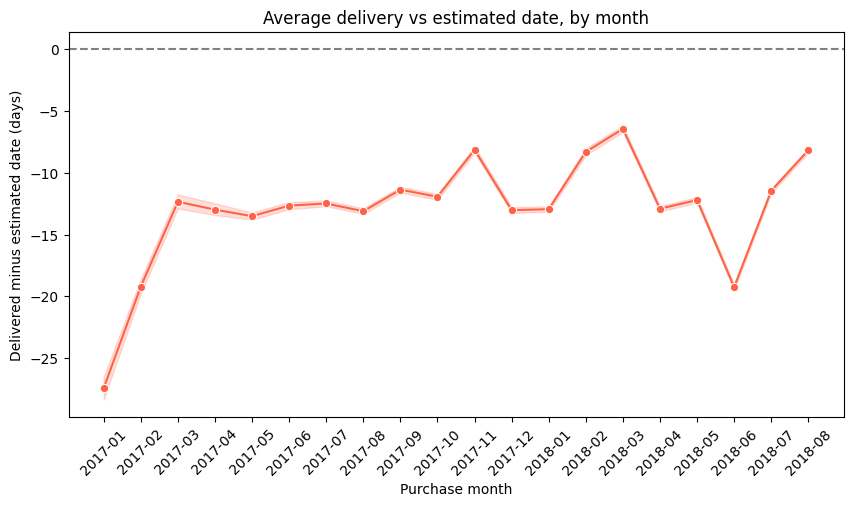

In [85]:
import seaborn as sns

d2 = delivered.copy()
d2["diff_days"] = (d2["order_delivered_customer_date"] - d2["order_estimated_delivery_date"]).dt.days
d2["month"] = d2["order_purchase_timestamp"].dt.to_period("M").astype(str)
d2 = d2[(d2["month"] >= "2017-01") & (d2["month"] <= "2018-08")]
d2 = d2.sort_values("month")
plt.figure(figsize=(10, 5))
sns.lineplot(data=d2, x="month", y="diff_days", marker="o", color="tomato")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=45)
plt.xlabel("Purchase month")
plt.ylabel("Delivered minus estimated date (days)")
plt.title("Average delivery vs estimated date, by month")
plt.show()

In [86]:
d = delivered.merge(customers_clean[["customer_id", "customer_state"]], on="customer_id", how="left")
by_state = d.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_pct=("is_late", lambda s: round(s.mean() * 100, 1)),
    avg_days=("delivery_days", "mean")
).round(1)
by_state = by_state[by_state["orders"] >= 100].sort_values("late_pct", ascending=False)
print("Top 10 States by Late Delivery Percentage:")
display(by_state.head(10))
print("\nBottom 5 States by Late Delivery Percentage:")
display(by_state.tail(5))

Top 10 States by Late Delivery Percentage:


,orders,late_pct,avg_days
customer_state,,,
AL,397,23.9,24.0
MA,717,19.7,21.1
PI,476,16.0,19.0
CE,1279,15.3,20.8
SE,335,15.2,21.0
BA,3256,14.0,18.9
RJ,12350,13.5,14.8
TO,274,12.8,17.2
PA,946,12.4,23.3



Bottom 5 States by Late Delivery Percentage:


,orders,late_pct,avg_days
customer_state,,,
SP,40494,5.9,8.3
MG,11354,5.6,11.5
PR,4923,5.0,11.5
AM,145,4.1,26.0
RO,243,2.9,18.9


In [87]:
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
r = (reviews.sort_values("review_creation_date").drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
d = d.merge(r, on="order_id", how="left")
print(d.groupby("is_late")["review_score"].mean().round(2))
print("Order with no review:", d["review_score"].isna().sum())

is_late
False    4.29
True     2.57
Name: review_score, dtype: float64
Order with no review: 646


Late orders average 2.57 stars against 4.29 for on-time orders, a gap of 1.72 stars. This is an association, not proof of cause.

           revenue  orders
month                     
2016-09     134.97       1
2016-10   40325.11     265
2016-12      10.90       1
2017-01  111798.36     750
2017-02  234223.40    1653
2017-03  359198.85    2546
2017-04  340669.68    2303
2017-05  489338.25    3546
2017-06  421923.37    3135
2017-07  481604.52    3872
2017-08  554699.70    4193
2017-09  607399.67    4150
2017-10  648247.65    4478
2017-11  987765.37    7289
2017-12  726033.19    5513
2018-01  924645.00    7069
2018-02  826437.13    6555
2018-03  953356.25    7003
2018-04  973534.09    6798
2018-05  977544.69    6749
2018-06  856077.86    6099
2018-07  867953.46    6159
2018-08  838576.64    6351


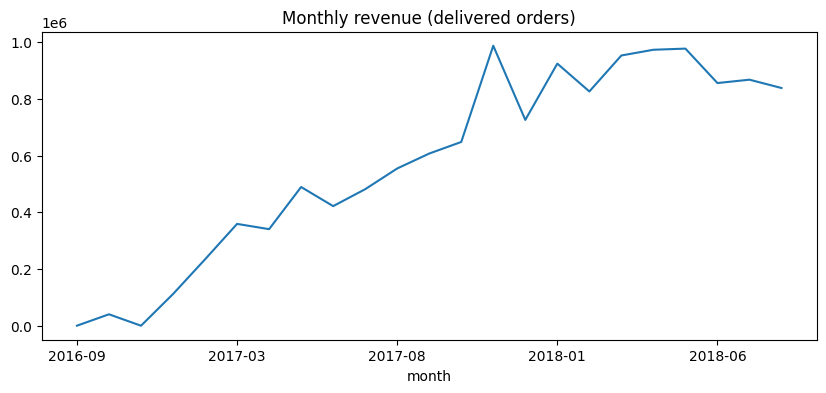

In [88]:
import matplotlib.pyplot as plt
items = order_items_clean.merge(orders_clean[["order_id", "order_status", "order_purchase_timestamp"]], on="order_id")
items = items[items["order_status"] == "delivered"].copy()
items["month"] = pd.to_datetime(items["order_purchase_timestamp"]).dt.to_period("M").astype(str)
monthly = items.groupby("month").agg(revenue=("price", "sum"), orders=("order_id", "nunique"))
print(monthly)
monthly["revenue"].plot(kind="line", figsize=(10, 4), title="Monthly revenue (delivered orders)")
plt.show()

Monthly revenue grew through 2017 and peaked in November 2017(987,765), then stayed roughly flat in 2018. The first months of 2016 have very few orders, so they are not a trend.

## 5. SQL (validated against pandas)

In [89]:
import sqlite3
conn = sqlite3.connect("olist_clean.db")
orders_clean.to_sql("orders", conn, index=False, if_exists="replace")
order_items_clean.to_sql("order_items", conn, if_exists="replace", index=False)
customers_clean.to_sql("customers", conn, if_exists="replace", index=False)

for t, df in [("orders", orders_clean), ("order_items", order_items_clean), ("customers", customers_clean)]:
  n = pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", conn)["n"][0]
  print(t, "- DB Count:", n, "| DF Count:", len(df), "-> OK" if n == len(df) else "-> MISMATCH")

orders - DB Count: 99441 | DF Count: 99441 -> OK
order_items - DB Count: 112650 | DF Count: 112650 -> OK
customers - DB Count: 99441 | DF Count: 99441 -> OK


In [90]:
q1 = "SELECT * FROM orders LIMIT 5"
q2 = "SELECT * FROM order_items LIMIT 5"
q3 = "SELECT * FROM customers LIMIT 5"

for name, q in [("Orders", q1), ("Order Items", q2), ("Customers", q3)]:
  print(f"--- Previewing Table: {name} ---")
  display(pd.read_sql(q, conn))
  print("\n")

--- Previewing Table: Orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8.436574,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13.782037,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9.394213,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13.208750,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2.873877,0




--- Previewing Table: Order Items ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14




--- Previewing Table: Customers ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [91]:
for name, q in [("Monthly revenue", q1), ("Late rate by state", q2), ("Month-over-month growth", q3)]:
  print("---", name, "---")
  print(pd.read_sql(q, conn).to_string(index=False))
  print()

--- Monthly revenue ---
                        order_id                      customer_id order_status order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date  delivery_days  late_delivery
e481f51cbdc54678b7cc49136f2d6af7 9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00       8.436574              0
53cdb2fc8bc7dce0b6741e2150273451 b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27          2018-07-26 14:31:00           2018-08-07 15:27:45           2018-08-13 00:00:00      13.782037              0
47770eb9100c2d0c44946d9cf07ec65d 41ce2a54c0b03bf3443c3d931a367089    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23          2018-08-08 13:50:00           2018-08-17 18:06:29           2018-09-04 00:00:00       9.394213              0
949d

In [92]:
sql = """
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month, ROUND(SUM(i.price)) AS revenue
FROM orders o JOIN order_items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
"""
print(pd.read_sql(sql, conn))

      month   revenue
0   2016-09     135.0
1   2016-10   40325.0
2   2016-12      11.0
3   2017-01  111798.0
4   2017-02  234223.0
5   2017-03  359199.0
6   2017-04  340670.0
7   2017-05  489338.0
8   2017-06  421923.0
9   2017-07  481605.0
10  2017-08  554700.0
11  2017-09  607400.0
12  2017-10  648248.0
13  2017-11  987765.0
14  2017-12  726033.0
15  2018-01  924645.0
16  2018-02  826437.0
17  2018-03  953356.0
18  2018-04  973534.0
19  2018-05  977545.0
20  2018-06  856078.0
21  2018-07  867953.0
22  2018-08  838577.0


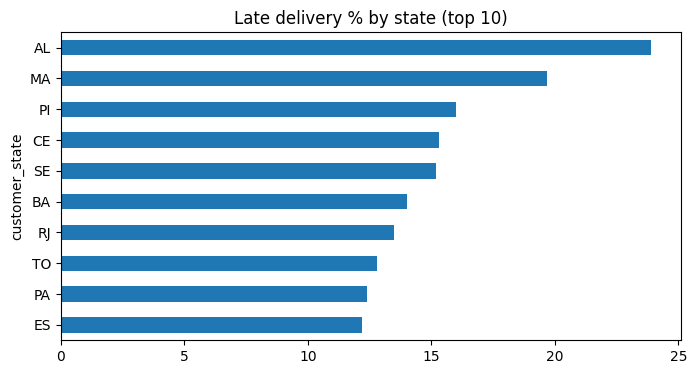

In [93]:
by_state["late_pct"].head(10).plot(kind="barh", figsize=(8, 4), title="Late delivery % by state (top 10)")
plt.gca().invert_yaxis()
plt.show()

The chart shows the late-delivery rate for the 10 states with the highest rates. AL is highest at 23.9%, about 3 times the national average of 8.1%. SP, the biggest market, has one of the lowest rates (5.9%).

## 6. Key findings
- 8.1% of 96,470 delivered orders arrived after the estimated date. Average delivery time is 12.1 days.

- Late rates are highest in AL (23.9%), MA (19.7%), PI (16.0%) and CE (15.3%), and lowest in SP (5.9%)

- Late orders average 2.57 stars, against 4.29 stars for on-time orders. This is an association, not proof of cause.

- Monthly revenue grew through 2017, peaked in November 2017 (987,765), then stayed roughly flat in 2018.

## Notes
- Revenue = sum of item prices for delivered orders, excluding freight.

- 646 delivered orders have no review and are left out of the score averages. Where an order had several reviews, the latest one is used.

- States with fewer than 100 orders are excluded from late-rate rankings.

- SQL monthly revenue was validated against pandas.

## 7. Export data for the dashboard

In [94]:
from google.colab import files

monthly.reset_index().to_csv("monthly_revenue.csv", index=False)
by_state.reset_index().to_csv("late_by_states.csv", index=False)
pd.DataFrame({
    "total_revenue": [round(total_revenue, 2)],
    "total_orders": [total_orders],
    "avg_order_value": [round(aov, 2)],
    "late_pct": [round(delivered["is_late"].mean() * 100, 1)],
    "avg_delivery_days": [round(delivered["delivery_days"].mean(), 1)],
    "score_on_time": [round(d[d["is_late" ] == False]["review_score"].mean(), 2)],
    "score_late": [round(d[d["is_late" ] == True]["review_score"].mean(), 2)],
}).to_csv("kpis.csv", index=False)


In [95]:
print("Headline revenue:", round(total_revenue))
print("Sum of monthly chart:", round(monthly["revenue"].sum()))
print("Headline orders:", total_orders, "| Delivered orders:", len(delivered))

Headline revenue: 13221498
Sum of monthly chart: 13221498
Headline orders: 96478 | Delivered orders: 96470
